##### Notebook for fitting the shape from the point data using the same fourier fit from the CALM class
##### This was done to hopefully create an upscaled version of the distribution for the points folder

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from fourier_core import Fourier_Series_Function

In [ ]:
# Load and inspect the point directory

current_dir = os.getcwd()
point_dir = os.path.join(current_dir, "..", "System", "point")

files = os.listdir(point_dir)

def _load_dat_file(file_path):
    if "Outer" in file_path:
        print("Loading OuterBM.dat file...")
        rows_to_skip = 4  # Number of rows to skip at the beginning of the file
        column_line_index = 2  # The line index where the column names are located (0-based)
    else:
        print("Loading InnerBM.dat file...")
        rows_to_skip = 3  # Number of rows to skip at the beginning of the file
        column_line_index = 1  # The line index where the column names are located (0-based)
    
    # First we extract the column names from the second line of the file
    with open(file_path, 'r') as f:
        lines = f.readlines()
        column_names = lines[column_line_index].strip().split()[1:-1]
    
    # Then load the data into a pandas DataFrame, skipping the first three lines
    DF = pd.read_csv(file_path, skiprows=rows_to_skip, names=column_names, delimiter=r'\s+')
        
    H = 0.5 * (DF['C1'] + DF['C2']) # Mean curvature
    pos = DF[['X', 'Y', 'Z']].values
    area = DF['area'].values
    
    return DF, H, pos, area

Data_inner, H_inner, pos_inner, area_inner = _load_dat_file(os.path.join(point_dir, "InnerBM.dat"))
Data_outer, H_outer, pos_outer, area_outer = _load_dat_file(os.path.join(point_dir, "OuterBM.dat"))

Loading InnerBM.dat file...
Loading OuterBM.dat file...


1500


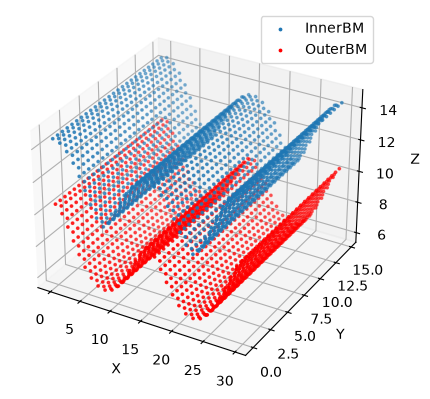

In [75]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(pos_inner[:, 0], pos_inner[:, 1], pos_inner[:, 2], s=3, label='InnerBM')
ax.scatter(pos_outer[:, 0], pos_outer[:, 1], pos_outer[:, 2], s=3, c='r', label='OuterBM')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()


print(len(pos_inner))

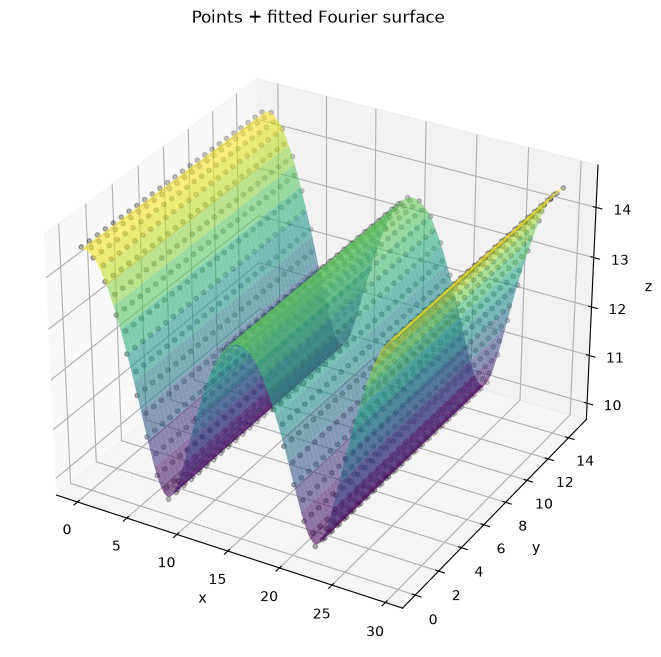

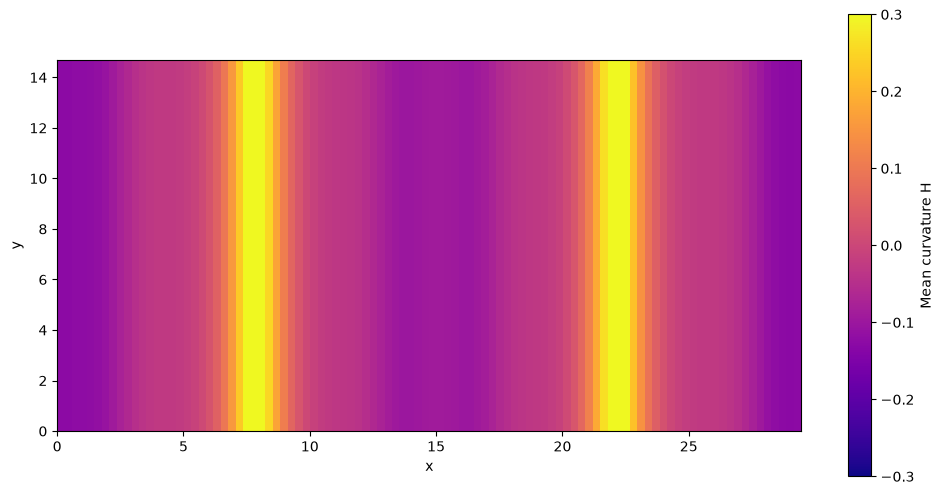

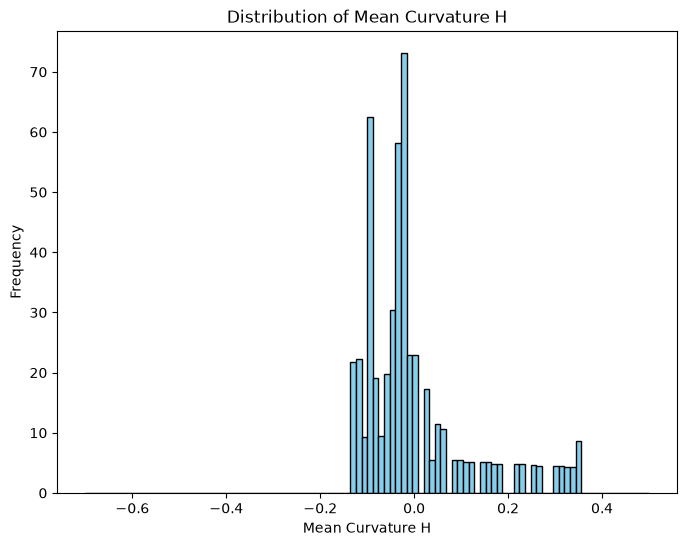

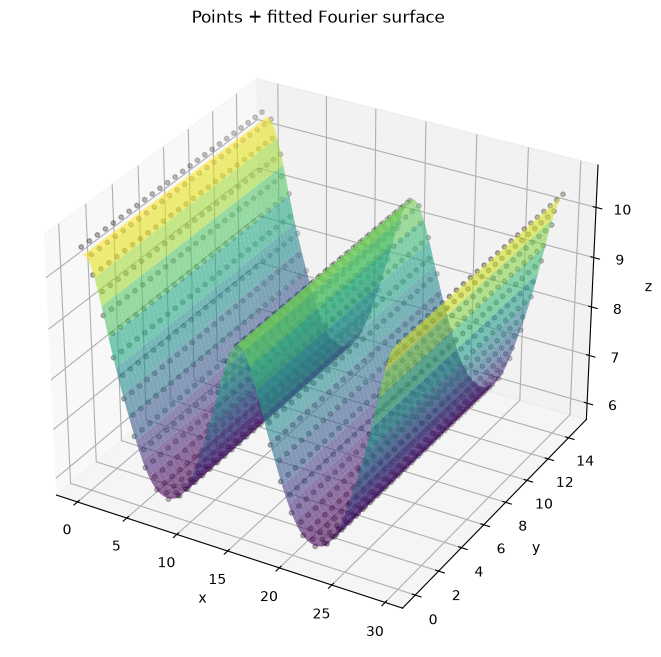

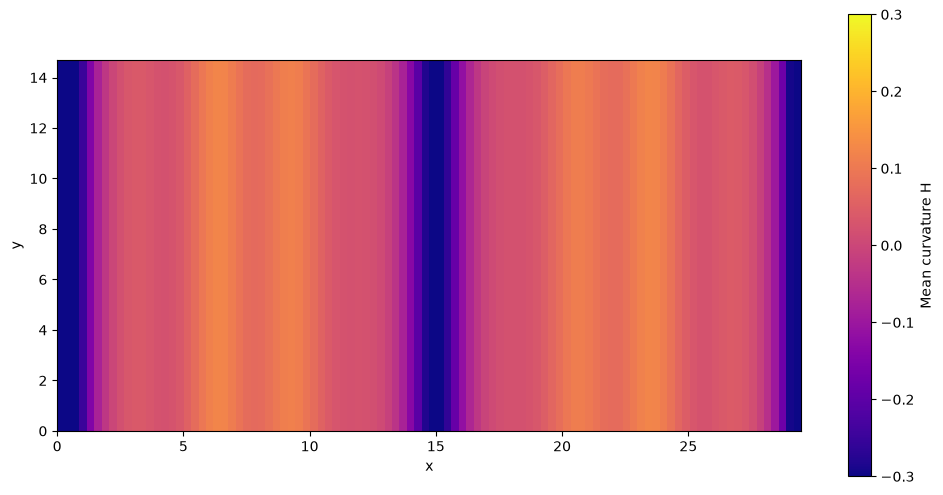

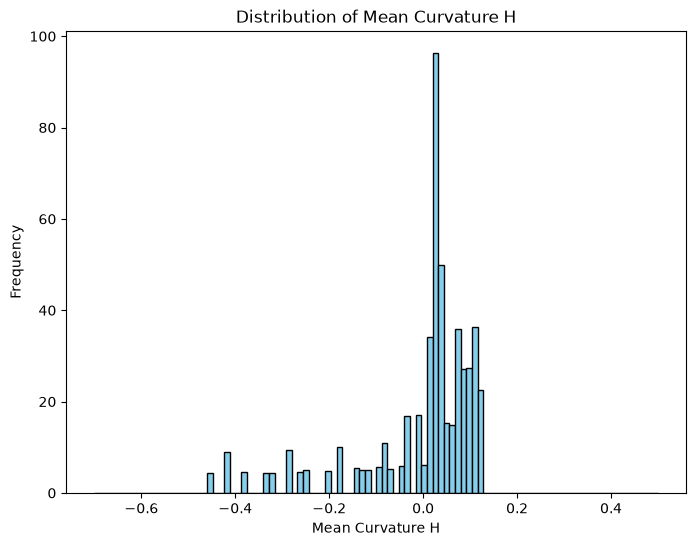

In [ ]:
def calc_curvatures(positions, Nx, Ny, Ngrid=100):

    Lx, Ly = max(positions[:, 0]), max(positions[:, 1])

    positions = np.array([positions[:, 0], positions[:, 1], positions[:, 2]])

    fourierClass = Fourier_Series_Function(Lx, Ly, Nx, Ny)
    fourierClass.Fit(positions)
    
    xg = np.linspace(0, Lx, Ngrid)
    yg = np.linspace(0, Ly, Ngrid)
    Xg, Yg = np.meshgrid(xg, yg)
    Zg = fourierClass.Z(Xg, Yg)

    H, K, k1, k2, dirs1, dirs2 = fourierClass.ShapeOperatorCurvatures(Xg, Yg)
    
    return H, K, k1, k2, dirs1, dirs2, Xg, Yg, Zg, positions, Lx, Ly


# Calc area
def calc_surface_area(positions, boxsize):
    """Calculates the surface area of each grid from the parametrizable surface element dA = np.length(np.cross(r_x, r_y))*dx*dy. 
    Scales the length according to the boxsize
    """
    positions = np.reshape(positions, (100,100)) # Reshaping the height array to be 100x100, as it should be
    
    Nx, Ny = positions.shape
    # What is the difference between each grid point
    dx = boxsize[0]/Nx 
    dy = boxsize[1]/Ny

    # Calculate the gradient from a central scheme for the in between points, and a forward/backward scheme at edges
    hy, hx = np.gradient(positions, dy, dx)    
    
    # Compute the area of each element according to the area of a parametrizable surface
    grid_area = np.sqrt(1+hx**2+hy**2)*(dx*dy)
    return grid_area, hx, hy



H_all = []
A_all = []
for pos in [pos_inner, pos_outer]:
    H, K, k1, k2, dirs1, dirs2, Xg, Yg, Zg, positions, Lx, Ly = calc_curvatures(pos, Nx=8, Ny=0, Ngrid=100)
    A, hx, hy = calc_surface_area(Zg, boxsize=(Lx, Ly))    

    H_all.append(H)
    A_all.append(A)

    # Plotting
    fig = plt.figure(figsize=(18, 8))

    ax1 = fig.add_subplot(1, 2, 1, projection="3d")
    ax1.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color="k", s=10, alpha=0.6, label="data")
    ax1.plot_surface(Xg, Yg, Zg, cmap="viridis", alpha=0.6, linewidth=0)
    ax1.set_title("Points + fitted Fourier surface")
    ax1.set_xlabel("x")
    ax1.set_ylabel("y")
    ax1.set_zlabel("z")


    # Curvature profile
    fig, ax = plt.subplots(figsize=(12, 6))
    im = ax.imshow(H, extent=(0, Lx, 0, Ly), origin="lower", cmap="plasma", vmin=-0.3, vmax=0.3)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    fig.colorbar(im, ax=ax, label="Mean curvature H")


    # Curvature distribution
    H_flat = H.flatten()
    n_bins = 100
    bin_range = (-0.7, 0.5)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.hist(H_flat, bins=n_bins, range=bin_range, color="skyblue", edgecolor="black", weights=A.flatten())
    ax.set_title("Distribution of Mean Curvature H")
    ax.set_xlabel("Mean Curvature H")
    ax.set_ylabel("Frequency")
    


In [ ]:
# Save the combined array of mean curvatures for both inner and outer surfaces
H_all = np.array(H_all).flatten()
A_all = np.array(A_all).flatten()
np.save("H_all_upscaled.npy", H_all)
np.save("A_all_upscaled.npy", A_all)